# Werkplaats blok 2 projectopdracht - Voorspel de Koers!
We gaan proberen of we een voorspellingsmodel kunnen maken dat de koers van een bepaald financieel product voorspelt op basis van algemene macro-economische grootheden en/of grondstoffenprijzen.
<p>
Daarvoor gaan we eerst data verzamelen van de financiele producten (aandelen, obligaties, crypto's), grondstoffen en macro-economische grootheden (inflatie, rente, olieprijs etc).
<p>
Data inlezen doen we met Yahoo Finance. Dat gaan we dus eerst installeren:

In [ ]:
! pip install pandas-datareader==0.10.0
! pip install yfinance
! pip install --upgrade yfinance

#Clear output
from google.colab import output
output.clear()

Vervolgens kunnen we de library importeren met import pandas_datareader.data as web. Daarna kunnen we de web.DataReader() functie gebruiken om data in te lezen uit (bijv) de Yahoo Finance database. We gebruiken [tz.localize(None)](https://pandas.pydata.org/docs/reference/api/pandas.DatetimeIndex.tz_localize.html) om ervoor te zorgen dat er slechts 1 koers per datum wordt ingelezen.

In [ ]:
import pandas as pd
import pandas_datareader.data as web
import yfinance as yf
import datetime as dt
from datetime import date

In [ ]:
#yf.pdr_override() #You don't need to use yf.pdr_override(). With the latest versions of yfinance, yf.download is already using the internal yfinance data fetching methods by default.

start = dt.datetime(2018,11,12)
end = dt.datetime(2024,11,12)

apple = yf.download('AAPL', start, end).tz_localize(None)
apple

[*********************100%***********************]  1 of 1 completed


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,,
2018-11-12,46.364468,48.542500,49.962502,48.447498,49.750000,204542000
2018-11-13,45.901241,48.057499,49.294998,47.862499,47.907501,187531600
2018-11-14,44.604660,46.700001,48.619999,46.482498,48.474998,243204000
2018-11-15,45.705437,47.852501,47.992500,46.724998,47.097500,185915200
2018-11-16,46.211651,48.382500,48.742500,47.365002,47.625000,147713200
...,...,...,...,...,...,...
2024-11-05,223.204422,223.449997,223.949997,221.139999,221.800003,28111300
2024-11-06,222.475235,222.720001,226.070007,221.190002,222.610001,54561100


Een fijn grafiekje wellicht? Daarvoor hebben we natuurlijk wel de matplotlib library nodig.

Text(0.5, 1.0, 'Slotkoers Apple')

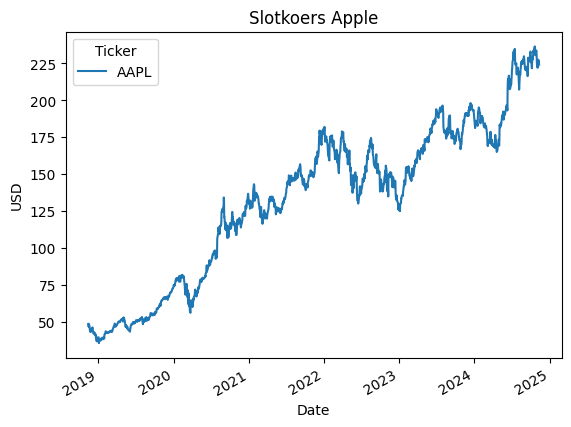

In [ ]:
import matplotlib.pyplot as plt # we gebruiken plt als afkorting om rechtstreeks met matplotlib te praten

apple.plot(y="Close") # we gebruiken y="" om aan te geven wat we op de y-as willen hebben
plt.ylabel("USD") # y-as naam geven
plt.title("Slotkoers Apple") # Grafiek een naam geven

Laten we 2 crypto's aan onze portfolio toevoegen:

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


Text(0.5, 1.0, 'Slotkoers Ethereum')

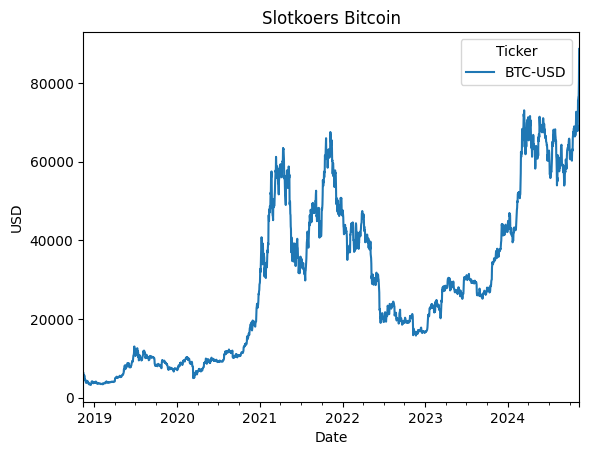

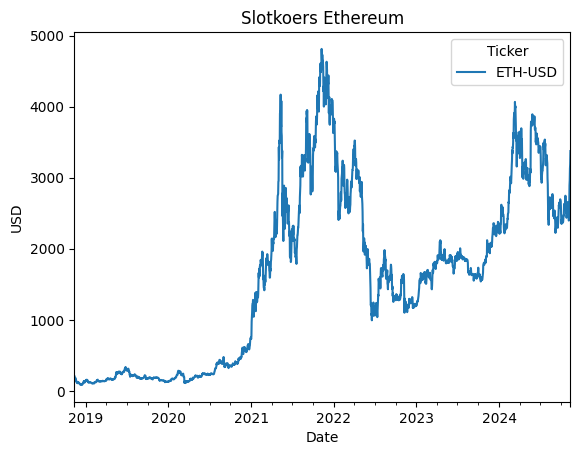

In [ ]:
btc = yf.download('BTC-USD', start, end).tz_localize(None)
eth = yf.download('ETH-USD', start, end).tz_localize(None)

btc.plot(y="Close")
plt.ylabel("USD")
plt.title("Slotkoers Bitcoin")
eth.plot(y="Close")
plt.ylabel("USD")
plt.title("Slotkoers Ethereum")

En nu maken we een portfolio:<br>
we voegen de drie datasets samen in 1 dataframe.

In [ ]:
portfolio = pd.concat([apple, btc, eth], axis=1)
print(portfolio)

Price        Adj Close       Close        High         Low        Open  \
Ticker            AAPL        AAPL        AAPL        AAPL        AAPL   
Date                                                                     
2018-11-12   46.364468   48.542500   49.962502   48.447498   49.750000   
2018-11-13   45.901241   48.057499   49.294998   47.862499   47.907501   
2018-11-14   44.604660   46.700001   48.619999   46.482498   48.474998   
2018-11-15   45.705437   47.852501   47.992500   46.724998   47.097500   
2018-11-16   46.211651   48.382500   48.742500   47.365002   47.625000   
...                ...         ...         ...         ...         ...   
2024-11-07  227.229996  227.479996  227.880005  224.570007  224.630005   
2024-11-08  226.960007  226.960007  228.660004  226.410004  227.169998   
2024-11-09         NaN         NaN         NaN         NaN         NaN   
2024-11-10         NaN         NaN         NaN         NaN         NaN   
2024-11-11  224.229996  224.229996  22

Als we kijken naar het Data Frame hierboven zien we dat er een aantal dingen mis gaan met het samenvoegen. We kunnen 2 dingen vinden.

Ten eerste zijn de namen van de kolommen niet zo handig. We kunnen nu niet meer zien welke kolom bij welk aandeel hoort. Daarnaast wordt het met 18 kolommen ook een beetje onoverzichtelijk, en zouden we misschien ook alleen naar de prijs op het moment dat de beurs sluit kunnen kijken.

Als tweede zijn er de NaN die we op verschillende plekken zien. NaN staat voor "Not a Number", dus we hebben voor dit stuk in het data frame geen getallen om in te vullen.

Gelukkig hebben we ook voor al deze problemen een oplossing. Sommige oplossingen zijn vrij eenvoudig, maar andere zijn wat complexer.

# Kolomnamen aanpassen
We willen de namen van onze kolommen duidelijker maken. De makkelijkste manier om dat te doen is om op een automatische manier achter iedere kolomnaam de naam van het aandeel te plakken.

Dan krijg je in het samengevoegde Data Frame in plaats van 3 kolommen die allemaal "Open" heten een Data Frame met kolommen als: ["Open_aandeel1", "Open_aandeel2", "Open_aandeel3", ...]

Gelukkig heeft ons Data Frame inderdaad een functie om de namen van alle kolommen aan te passen. Dat is de add_suffix() functie. Suffix is het Engelse woord voor achtervoegsel, dus we voegen met deze functie aan alle kolomnamen een achtervoegsel toe.

In [ ]:
portfolio = pd.concat([apple.add_suffix("_Apple"), btc.add_suffix("_Bitcoin"), eth.add_suffix("_Ethereum")], axis=1)
portfolio

Price,Adj Close_Apple,Close_Apple,High_Apple,Low_Apple,Open_Apple,Volume_Apple,Adj Close_Bitcoin,Close_Bitcoin,High_Bitcoin,Low_Bitcoin,Open_Bitcoin,Volume_Bitcoin,Adj Close_Ethereum,Close_Ethereum,High_Ethereum,Low_Ethereum,Open_Ethereum,Volume_Ethereum
Ticker,AAPL_Apple,AAPL_Apple,AAPL_Apple,AAPL_Apple,AAPL_Apple,AAPL_Apple,BTC-USD_Bitcoin,BTC-USD_Bitcoin,BTC-USD_Bitcoin,BTC-USD_Bitcoin,BTC-USD_Bitcoin,BTC-USD_Bitcoin,ETH-USD_Ethereum,ETH-USD_Ethereum,ETH-USD_Ethereum,ETH-USD_Ethereum,ETH-USD_Ethereum,ETH-USD_Ethereum
Date,,,,,,,,,,,,,,,,,,
2018-11-12,46.364468,48.542500,49.962502,48.447498,49.750000,204542000.0,6371.270020,6371.270020,6434.209961,6360.470215,6411.759766,4295770000,210.417999,210.417999,212.623001,208.923996,211.513000,1452380000
2018-11-13,45.901241,48.057499,49.294998,47.862499,47.907501,187531600.0,6359.490234,6359.490234,6395.270020,6342.669922,6373.189941,4503800000,206.826004,206.826004,210.514999,206.134995,210.149002,1610260000
2018-11-14,44.604660,46.700001,48.619999,46.482498,48.474998,243204000.0,5738.350098,5738.350098,6371.549805,5544.089844,6351.240234,7398940000,181.397003,181.397003,207.044998,174.084000,206.533997,2595330000
2018-11-15,45.705437,47.852501,47.992500,46.724998,47.097500,185915200.0,5648.029785,5648.029785,5774.819824,5358.379883,5736.149902,7032140000,180.806000,180.806000,184.251007,170.188995,181.899002,2638410000
2018-11-16,46.211651,48.382500,48.742500,47.365002,47.625000,147713200.0,5575.549805,5575.549805,5657.020020,5498.939941,5645.319824,5279320000,175.177002,175.177002,181.350006,173.126007,180.865005,2015330000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-11-07,227.229996,227.479996,227.880005,224.570007,224.630005,42137700.0,75904.859375,75904.859375,76943.117188,74480.421875,75637.085938,63467654989,2895.585449,2895.585449,2918.744385,2701.590820,2724.005859,35352318438
2024-11-08,226.960007,226.960007,228.660004,226.410004,227.169998,38328800.0,76545.476562,76545.476562,77252.750000,75648.742188,75902.835938,55176858003,2962.296631,2962.296631,2983.744873,2889.484375,2895.597900,32303261101


Nu hebben we nog het probleem dat ons Data Frame een heleboel kolommen heeft die we niet gaan gebruiken. Eigenlijk willen we die er allemaal uit filteren.

We zouden met de .drop("kolomnaam", axis=1) functie wel allemaal kolommen kunnen verwijderen, maar met 18 kolommen is dat best wat werk. In dit geval is het makkelijker om met .loc[:, ["Kolom1", "Kolom2", ...]] de kolommen te selecteren die we willen houden.

In [ ]:
portfolio_gefilterd = portfolio.loc[:, ["Close_Apple", "Close_Bitcoin", "Close_Ethereum"]]
portfolio_gefilterd

Price,Close_Apple,Close_Bitcoin,Close_Ethereum
Ticker,AAPL_Apple,BTC-USD_Bitcoin,ETH-USD_Ethereum
Date,,,
2018-11-12,48.542500,6371.270020,210.417999
2018-11-13,48.057499,6359.490234,206.826004
2018-11-14,46.700001,5738.350098,181.397003
2018-11-15,47.852501,5648.029785,180.806000
2018-11-16,48.382500,5575.549805,175.177002
...,...,...,...
2024-11-07,227.479996,75904.859375,2895.585449
2024-11-08,226.960007,76545.476562,2962.296631


De dubbele kolomnamen zijn niet handig, passen we ook aan:

In [ ]:
portfolio_gefilterd.columns = ['Close_Apple', 'Close_Bitcoin', 'Close_Ethereum']
portfolio_gefilterd

,Close_Apple,Close_Bitcoin,Close_Ethereum
Date,,,
2018-11-12,48.542500,6371.270020,210.417999
2018-11-13,48.057499,6359.490234,206.826004
2018-11-14,46.700001,5738.350098,181.397003
2018-11-15,47.852501,5648.029785,180.806000
2018-11-16,48.382500,5575.549805,175.177002
...,...,...,...
2024-11-07,227.479996,75904.859375,2895.585449
2024-11-08,226.960007,76545.476562,2962.296631
2024-11-09,NaN,76778.867188,3131.144531


En we eindigen natuurlijk met een fijn grafiekje:

Text(0.5, 1.0, 'Slotkoersen Apple, Bitcoin & Ethereum')

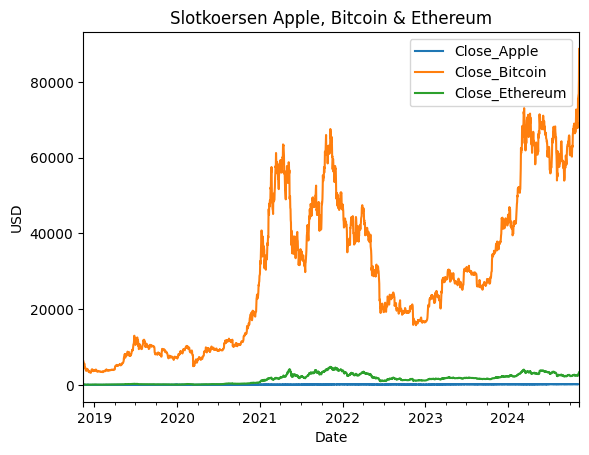

In [ ]:
portfolio_gefilterd.plot()
plt.ylabel("USD")
plt.title("Slotkoersen Apple, Bitcoin & Ethereum")

# NaN
Bepalen wat je het beste kunt doen met NaNs (plekken waar we geen waardes hebben) is een van de lastigere dingen aan data opschonen.

De keuzes die je maakt kunnen veel invloed hebben op het resultaat dat je uiteindelijk krijgt, terwijl je dat soms niet meer door hebt. Daarom is de keuze wat je doet met NaNs heel lastig en ook heel belangrijk.
<p>
Uiteindelijk zijn er 2 mogelijkheden. We kunnen de data weggooien, of we kunnen nieuwe data er bij maken.

Om data weg te gooien hebben we de .dropna() functie. Hierdoor wordt iedere rij waar minstens 1 NaN in zit verwijdert. Hierdoor zijn er geen NaNs meer, maar verwijderen we ook data die soms wel goed was.

In [ ]:
nans_verwijderd = portfolio_gefilterd.dropna()
nans_verwijderd

,Close_Apple,Close_Bitcoin,Close_Ethereum
Date,,,
2018-11-12,48.542500,6371.270020,210.417999
2018-11-13,48.057499,6359.490234,206.826004
2018-11-14,46.700001,5738.350098,181.397003
2018-11-15,47.852501,5648.029785,180.806000
2018-11-16,48.382500,5575.549805,175.177002
...,...,...,...
2024-11-05,223.449997,69359.562500,2422.650635
2024-11-06,222.720001,75639.078125,2724.169189
2024-11-07,227.479996,75904.859375,2895.585449


# Imputeren
We kunnen ook waardes invullen op de plekken waar NaN zitten. Hiervoor gebruiken we de .fillna(). We kunnen bijvoorbeeld alle lege plekken vullen met 0. Hierdoor gaat er geen data verloren, maar ga je wel onbedoeld sommige resultaten veranderen.

In [ ]:
nans_gevuld = portfolio_gefilterd.fillna(0)
nans_gevuld

,Close_Apple,Close_Bitcoin,Close_Ethereum
Date,,,
2018-11-12,48.542500,6371.270020,210.417999
2018-11-13,48.057499,6359.490234,206.826004
2018-11-14,46.700001,5738.350098,181.397003
2018-11-15,47.852501,5648.029785,180.806000
2018-11-16,48.382500,5575.549805,175.177002
...,...,...,...
2024-11-07,227.479996,75904.859375,2895.585449
2024-11-08,226.960007,76545.476562,2962.296631
2024-11-09,0.000000,76778.867188,3131.144531


# Forward-fill & Back-fill
Een betrouwbaardere manier om data te vullen als je te maken hebt met aandelenwaardes is door middel van forward-fill.

Bij de waarde van beleggingen kom je vaak NaNs tegen op de dagen dat de beurzen gesloten zijn. Terwijl de koers van (crypto)munten dan nog wel beweegt, hebben we voor die dagen geen data van beursverhandelde aandelen. Zo hebben we vaak op feestdagen NaNs voor aandelen.

Hier komt de forward-fill methode het best van pas. We hebben hier de functie .ffill() voor, kort voor forward-fill. Met forward-fill gebruiken we de vorige waarde en vullen die in bij de NaN. Dit is voor de waarde van een aandeel intuitief, omdat de verhandelde waarde in de tussentijd ook niet is veranderd.

Het zal ook het gemiddelde iets anders maken dan de originele data, omdat we nieuwe waardes toevoegen. Ook hier valt dan te beargumenteren dat het gemiddelde verandert naar boven of beneden, afhankelijk van de forward fill-waardes.

In [ ]:
nans_gevuld = portfolio_gefilterd.ffill()
nans_gevuld

,Close_Apple,Close_Bitcoin,Close_Ethereum
Date,,,
2018-11-12,48.542500,6371.270020,210.417999
2018-11-13,48.057499,6359.490234,206.826004
2018-11-14,46.700001,5738.350098,181.397003
2018-11-15,47.852501,5648.029785,180.806000
2018-11-16,48.382500,5575.549805,175.177002
...,...,...,...
2024-11-07,227.479996,75904.859375,2895.585449
2024-11-08,226.960007,76545.476562,2962.296631
2024-11-09,226.960007,76778.867188,3131.144531


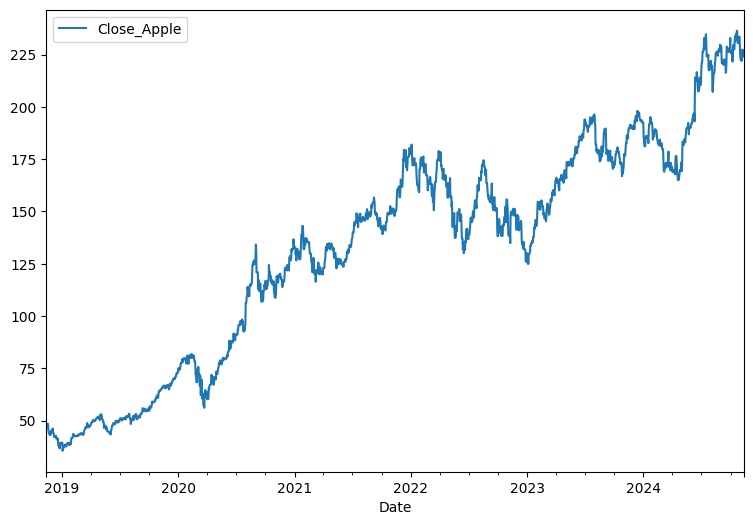

In [ ]:
nans_gevuld.plot(y="Close_Apple", figsize=(9, 6)) # Missende waardes gekopieerd
plt.show()

Forward-fill werkt natuurlijk niet als er geen vorige waarde is, bijvoorbeeld als je NaNs aan het begin van je Data Frame hebt. Dan kan je de .backfill() functie gebruiken om de NaNs te vullen met de eerst-volgende waarde.
<p>
Let Op: dit kunnnen we niet gebruiken voor de koersen van de crypto's, want die bestonden toen nog niet.

In [ ]:
nans_backgevuld = portfolio_gefilterd.backfill()
nans_backgevuld

<ipython-input-16-018ac5c2fabd>:1: FutureWarning: DataFrame.backfill/Series.backfill is deprecated. Use DataFrame.bfill/Series.bfill instead
  nans_backgevuld = portfolio_gefilterd.backfill()


,Close_Apple,Close_Bitcoin,Close_Ethereum
Date,,,
2018-11-12,48.542500,6371.270020,210.417999
2018-11-13,48.057499,6359.490234,206.826004
2018-11-14,46.700001,5738.350098,181.397003
2018-11-15,47.852501,5648.029785,180.806000
2018-11-16,48.382500,5575.549805,175.177002
...,...,...,...
2024-11-07,227.479996,75904.859375,2895.585449
2024-11-08,226.960007,76545.476562,2962.296631
2024-11-09,224.229996,76778.867188,3131.144531


Pandas data structures have two useful methods for detecting null data: isnull() and notnull(). Either one will return a Boolean mask over the data (= True or False).<br>
For example:

In [ ]:
nans_gevuld.isnull()

,Close_Apple,Close_Bitcoin,Close_Ethereum
Date,,,
2018-11-12,False,False,False
2018-11-13,False,False,False
2018-11-14,False,False,False
2018-11-15,False,False,False
2018-11-16,False,False,False
...,...,...,...
2024-11-07,False,False,False
2024-11-08,False,False,False
2024-11-09,False,False,False


In [ ]:
nans_gevuld.notnull()

,Close_Apple,Close_Bitcoin,Close_Ethereum
Date,,,
2018-11-12,True,True,True
2018-11-13,True,True,True
2018-11-14,True,True,True
2018-11-15,True,True,True
2018-11-16,True,True,True
...,...,...,...
2024-11-07,True,True,True
2024-11-08,True,True,True
2024-11-09,True,True,True


We hebben nu de data geschoond van NaN (voor zover mogelijk), maar nog niet gekeken of er 'vreemde' of foutieve data in de dataset aanwezig zijn. Zoals eerder in blok 1 gedaan, kunnen we hier met behulp van statistische gegevens onderzoek naar doen. Bijvoorbeeld door te kijken naar de minimum en maximum waardes en de standaardafwijking ten opzichte van het gemiddelde.<br>
Hiervoor gebruiken we het python-commando 'describe'.

In [ ]:
nans_gevuld.describe()

,Close_Apple,Close_Bitcoin,Close_Ethereum
count,2192.000000,2192.000000,2192.000000
mean,132.553838,29395.193925,1605.094042
std,53.195477,20124.197589,1232.347189
min,35.547501,3236.761719,84.308296
25%,79.793127,10143.916504,246.223846
50%,143.225006,26494.295898,1636.185242
75%,172.570007,43944.598633,2517.831116
max,236.479996,88701.484375,4812.087402


Conclusie?

# Histogrammen
Een mooi plaatje in de vorm van een histogram kan ook helpen.

array([[<Axes: title={'center': 'Close_Apple'}>,
        <Axes: title={'center': 'Close_Bitcoin'}>],
       [<Axes: title={'center': 'Close_Ethereum'}>, <Axes: >]],
      dtype=object)

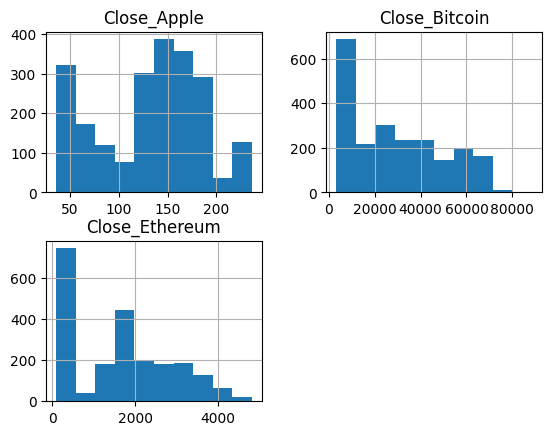

In [ ]:
nans_gevuld.hist()

De histogrammen hierboven waren heel simpel om te maken, maar zijn misschien niet zo mooi. Hier komt de kracht van parameters instellen echt goed tot zijn recht. Als je in de documentatie kijkt, zie je dat er 17 parameters zijn om in te stellen.

Het eerste dat we willen aanpassen is de layout. Het is natuurlijk niet mooi dat we twee histogrammen naast elkaar hebben en de volgende er onder. Het zou mooier zijn als we 1 rij hebben met alle 3 histogrammen naast elkaar.

In de documentatie staat een layout parameter die (rijen, kolommen) wil.

Daarnaast is de afbeelding wat te klein. Ook daar is een parameter voor, namelijk figsize.

Als laatste is het niet zo mooi dat de y-as niet overal hetzelfde is. Zelfs daar is een parameter voor, namelijk sharey. Die moet een waarde True of False krijgen. Door als parameter te zetten sharey=True wordt de y-as tussen alle histogrammen gedeeld.

Zo kunnen we een complexere regel code bouwen die de histogrammen precies maakt zoals wij willen.

array([[<Axes: title={'center': 'Close_Apple'}>,
        <Axes: title={'center': 'Close_Bitcoin'}>,
        <Axes: title={'center': 'Close_Ethereum'}>]], dtype=object)

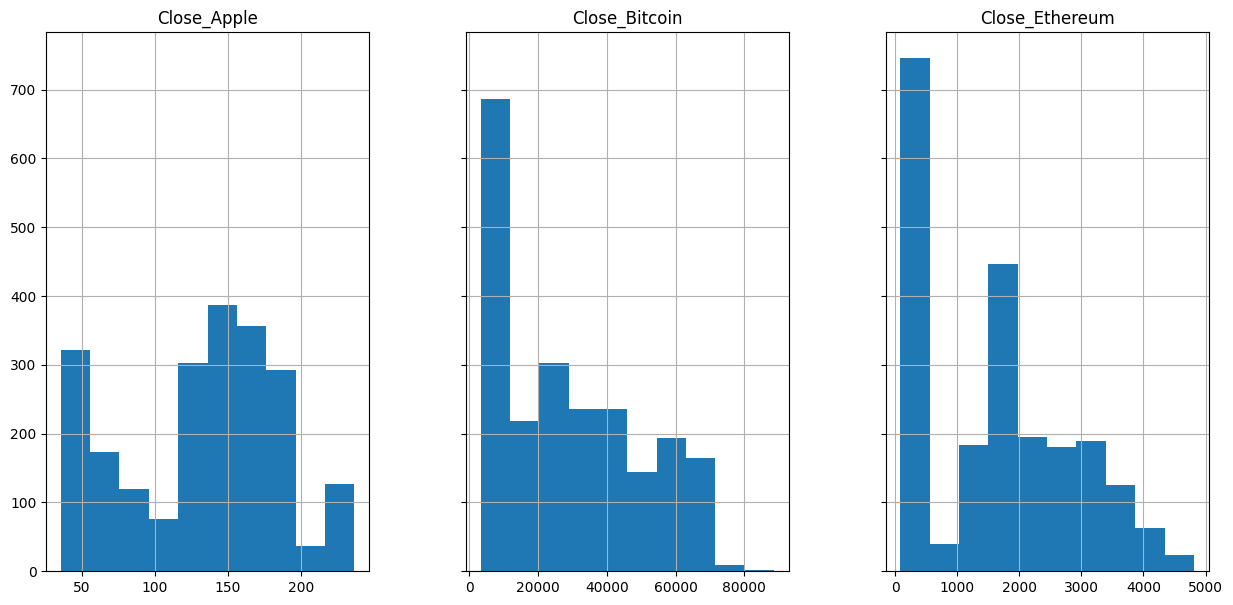

In [ ]:
nans_gevuld.hist(layout=(1, 3), figsize=(15, 7), sharey=True)

# Filteren
De meeste functies op een data frame geven ook weer een data frame terug. Dat betekent dat we opdrachten achter elkaar kunnen uitvoeren om zo de data steeds verder te verwerken.

Hieronder laten we dat zien. We gebruiken tail() om de laatste 5 rijen te selecteren. Daarna nemen we daarvan de "Close_Apple" kolom. Van die waardes nemen we vervolgens het gemiddelde.

In [ ]:
laatste_rijen = nans_gevuld.tail()

close_laatste_rijen = laatste_rijen.loc[:, ['Close_Apple']]

close_laatste_rijen.mean()

,0
Close_Apple,226.518002


In het voorbeeld hierboven zetten we iedere keer het resultaat in een nieuwe variabele. Dat houdt dingen soms wat overzichtelijker, maar het is ook niet altijd fijn om voor iedere stap een variabele te hebben.

We kunnen hier ook de verschillende opdrachten achter elkaar plakken. Daarmee worden de functies van links naar rechts uitgevoerd, steeds met het resultaat van de vorige functie.

Je ziet hieronder dat je dan hetzelfde resultaat krijgt, en maar 1 regel code nodig hebt:

In [ ]:
nans_gevuld.tail().loc[:, ['Close_Apple']].mean()

,0
Close_Apple,226.518002


Het combineren van opdrachten kan ons helpen om veel meer details te krijgen over onze data. Dit is vooral heel handig in combinatie met filters.

We hebben met .loc data geselecteerd op basis van de naam van de rij/kolom, maar we kunnen ook data selecteren op basis van bepaalde voorwaarden.

Vaak filter je op rijen, zodat je alleen de rijen overhoudt die relevant zijn. In de portfolio dataset kunnen we bijvoorbeeld filteren op aandeel of datum of koers.

Dit doen we door eerst te bepalen welke rijen aan onze voorwaarde voldoen. Vervolgens kunnen we deze rijen in .loc geven om zo alleen die rijen te selecteren.

In [ ]:
# Bepaal voor iedere rij of de Close_Apple > 100 dollar
rijen_Apple = nans_gevuld.loc[:, "Close_Apple"] > 100
rijen_Apple

,Close_Apple
Date,
2018-11-12,False
2018-11-13,False
2018-11-14,False
2018-11-15,False
2018-11-16,False
...,...
2024-11-07,True
2024-11-08,True
2024-11-09,True


Zoals je ziet gebruiken we voor filters enkele blokhaken. Dit geeft ons een serie van True en False voor iedere rij.

Deze serie kunnen we bij .loc gebruiken zodat alle rijen waar de Close_Apple > 100 worden geselecteerd.

In [ ]:
filtered_df = nans_gevuld.loc[nans_gevuld['Close_Apple'] > 100]
filtered_df

,Close_Apple,Close_Bitcoin,Close_Ethereum
Date,,,
2020-07-31,106.260002,11323.466797,345.554657
2020-08-01,106.260002,11759.592773,385.199707
2020-08-02,106.260002,11053.614258,370.671722
2020-08-03,108.937500,11246.348633,386.295166
2020-08-04,109.665001,11205.892578,389.875488
...,...,...,...
2024-11-07,227.479996,75904.859375,2895.585449
2024-11-08,226.960007,76545.476562,2962.296631
2024-11-09,226.960007,76778.867188,3131.144531


# Filters combineren
Om nog gedetailleerdere inzichten te krijgen kunnen we ook filters combineren. Dit doen we door eerst verschillende filters te maken, en ze daarna te combineren met & ("en"), en | ("of").

Zo kunnen we een filter maken voor alle data waar de Close_Apple > 150 is en de datum in 2022.

In [ ]:
apple_filter = nans_gevuld['Close_Apple'] > 150
datum_filter = nans_gevuld.index.isin(pd.date_range('2022-01-01', '2022-12-31'))

samenfilter = apple_filter & datum_filter

filter_gecombineerd = nans_gevuld.loc[samenfilter, :]
filter_gecombineerd

,Close_Apple,Close_Bitcoin,Close_Ethereum
Date,,,
2022-01-01,177.570007,47686.812500,3769.697021
2022-01-02,177.570007,47345.218750,3829.564941
2022-01-03,182.009995,46458.117188,3761.380371
2022-01-04,179.699997,45897.574219,3794.056641
2022-01-05,174.919998,43569.003906,3550.386963
...,...,...,...
2022-11-19,151.289993,16711.546875,1218.426758
2022-11-20,151.289993,16291.832031,1142.466675
2022-11-22,150.179993,16189.769531,1135.173462


# Werken met datum(s): super simpel??
Zeker, maar dan wel met de hulp van Gemini!

# Boxplot
Om te kijken of er uitschieters in de data zitten, kunnen we ook een boxplot maken:

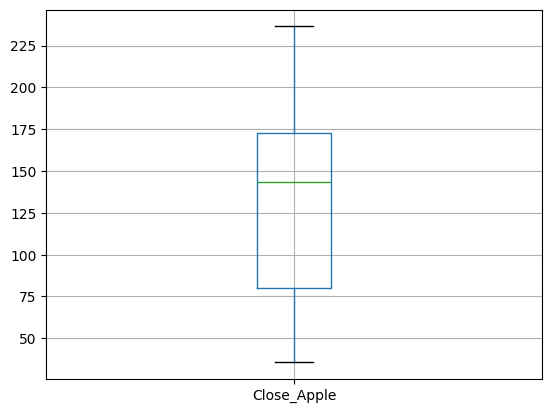

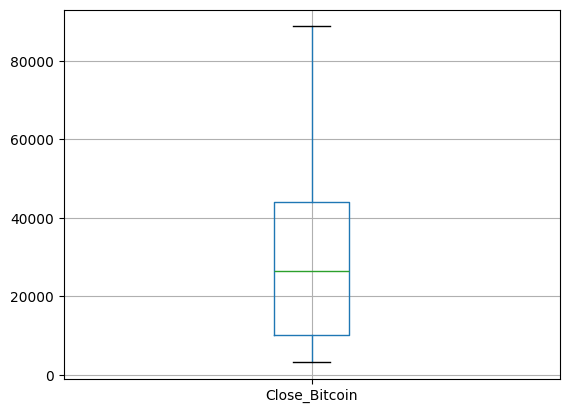

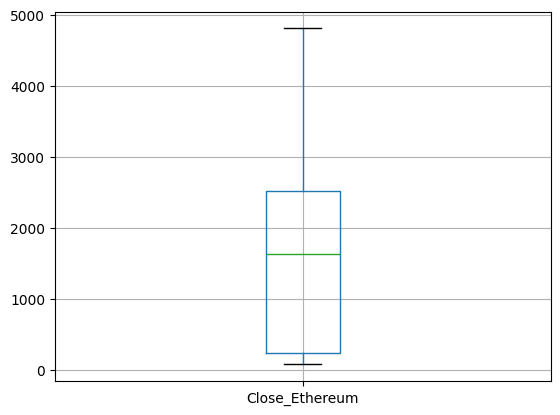

<Axes: >

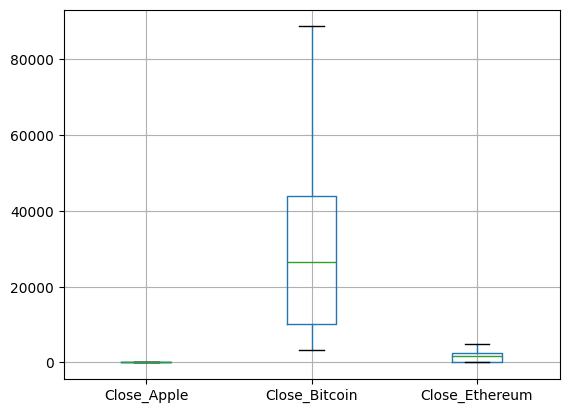

In [ ]:
data_1 = nans_gevuld.loc[:, ["Close_Apple"]]
data_2 = nans_gevuld.loc[:, ["Close_Bitcoin"]]
data_3 = nans_gevuld.loc[:, ["Close_Ethereum"]]

# Creating boxplot
bp1 = data_1.boxplot()
plt.show()
bp2 = data_2.boxplot()
plt.show()
bp3 = data_3.boxplot()
plt.show()

nans_gevuld.boxplot(column=["Close_Apple", "Close_Bitcoin","Close_Ethereum"])

Als je de grafieken nog mooier wilt maken: https://www.geeksforgeeks.org/box-plot-in-python-using-matplotlib/